# Problem Analysis Workshop C — Capital Bikeshare

**Group 7**

1. Sukhchain Singh (9111541)
2. Preethi (9125985)
3. Arya (9084843)

## Step 1 — Define the research question

**How well do weather and calendar variables predict daily Capital Bikeshare rentals in Washington, D.C.? Does multiple linear regression predict rentals more accurately than either of the two simple linear regression models?**

Our **target variable** is `cnt`, which is the total number of bikes rented on a given day. A **predictor** is a piece of information we use to estimate that total. Temperature, rainfall, and the day of the week are examples of predictors.

A **simple linear regression** uses one predictor at a time. Our team will compare two simple models, then use **multiple linear regression** to see whether combining several predictors improves accuracy. In my section, I prepare and check the data that the team will use for all three models.

## Step 2 — Choose and load the datasets

We chose the **Capital Bikeshare daily dataset** (`day.csv`) because it contains `cnt`, the total number of bikes rented each day. It also includes calendar information, such as the weekday and whether it was a holiday, along with basic weather measurements.

We added **Open-Meteo historical weather data** (`open_meteo_weather.csv`) for **Washington, D.C.**, using coordinates **38.90° N, 77.04° W**. We requested daily records from **January 1, 2011, through December 31, 2012**, using the **America/New_York** time zone.

We chose this weather dataset because it covers the same location and dates as the bike data and provides more detail. For example, the bike dataset has a general weather category, while Open-Meteo gives us the amount of rain, hours of precipitation, and duration of sunshine. Both files have one row per day, so we can match them by date.

[UCI Bike Sharing dataset](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset)  
[Open-Meteo Historical Weather documentation](https://open-meteo.com/en/docs/historical-weather-api)

In [2]:
from pathlib import Path

import pandas as pd
from IPython.display import display

# Look for the CSVs in the current folder's data folder,
# then check each parent folder.
current_folder = Path.cwd()

for folder in [current_folder, *current_folder.parents]:
    data_folder = folder / "data"
    if (data_folder / "day.csv").is_file() and (
        data_folder / "open_meteo_weather.csv"
    ).is_file():
        break
else:
    raise FileNotFoundError(f"Could not find both CSVs in a data folder above {current_folder}")

bike = pd.read_csv(data_folder / "day.csv")
weather = pd.read_csv(data_folder / "open_meteo_weather.csv", skiprows=3)

# Remove units from weather headers, such as "rain_sum (mm)".
weather.columns = weather.columns.str.strip().str.replace(
    r"\s+\([^)]*\)$", "", regex=True
)

print("Loading files from:", data_folder)

print("Bike dataset (rows, columns):", bike.shape)
display(bike.head(3))

print("Weather dataset (rows, columns):", weather.shape)
display(weather.head(3))

Loading files from: c:\Conestoga_Projects\DataAnalytics\Data_Analysis_Presentation1\data
Bike dataset (rows, columns): (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349


Weather dataset (rows, columns): (731, 20)


,time,rain_sum,snowfall_sum,precipitation_hours,shortwave_radiation_sum,daylight_duration,sunshine_duration,wind_gusts_10m_max,temperature_2m_max,temperature_2m_min,cloud_cover_mean,pressure_msl_mean,pressure_msl_max,pressure_msl_min,relative_humidity_2m_min,dew_point_2m_mean,wind_direction_10m_dominant,cloud_cover_max,cloud_cover_min,wind_speed_10m_max
0,2011-01-01,2.7,0.0,6.0,5.59,34147.85,14400.00,41.4,14.8,1.7,85,1018.5,1021.2,1015.6,69,6.0,197,100,0,17.7
1,2011-01-02,2.8,0.0,8.0,1.25,34189.21,0.00,42.5,14.6,0.5,78,1016.3,1020.2,1013.9,35,2.5,304,100,0,18.9
2,2011-01-03,0.0,0.0,0.0,10.22,34234.59,33210.34,37.4,3.5,-3.6,6,1023.8,1026.7,1020.7,34,-10.4,296,89,0,17.4


## Step 3 — Merge the datasets by date

The bike dataset stores its date in `dteday`, and the weather dataset stores it in `time`. We rename both columns to `date` and convert them to the same data type. The date becomes the **join key**, which is the field pandas uses to match records. After the merge, one row contains both the rental count and the weather measurements for that day.

We use a **left join** with the bike dataset on the left. This keeps every bike rental day and lets us see whether any of those dates are missing a weather record. We also use a **one-to-one check** because each date should appear only once in each file. This prevents duplicate weather records from creating extra rental rows.

The merge kept **731 daily records**, with **731 matched dates and 0 unmatched dates**. Every bike rental day has a corresponding weather record.

In [3]:
# Give both date columns the same name.
bike_by_date = bike.rename(columns={"dteday": "date"})
weather_by_date = weather.rename(columns={"time": "date"})

# Convert the date columns from text to the same pandas date type.
bike_by_date["date"] = pd.to_datetime(bike_by_date["date"], format="%Y-%m-%d")
weather_by_date["date"] = pd.to_datetime(weather_by_date["date"], format="%Y-%m-%d")

# Check that every row has a date before matching records.
assert bike_by_date["date"].notna().all(), "The bike dataset has missing dates."
assert weather_by_date["date"].notna().all(), "The weather dataset has missing dates."

# Keep all bike rental days and attach the weather for the same date.
merged = bike_by_date.merge(
    weather_by_date,
    on="date",
    how="left",
    validate="one_to_one",
    indicator=True
)

# The temporary _merge column shows which bike days found a weather match.
matched_days = merged["_merge"].eq("both").sum()
unmatched_days = merged["_merge"].eq("left_only").sum()

print("Rows after merging:", len(merged))
print("Days with a weather match:", matched_days)
print("Days without a weather match:", unmatched_days)

assert len(merged) == 731, "Expected 731 daily records after merging."
assert unmatched_days == 0, "Some bike rental days are missing a weather record."

# Remove the temporary column and preview the combined data.
merged = merged.drop(columns="_merge")
display(merged[["date", "cnt", "temp", "rain_sum", "sunshine_duration"]].head())

Rows after merging: 731
Days with a weather match: 731
Days without a weather match: 0


,date,cnt,temp,rain_sum,sunshine_duration
0,2011-01-01,985,0.344167,2.7,14400.00
1,2011-01-02,801,0.363478,2.8,0.00
2,2011-01-03,1349,0.196364,0.0,33210.34
3,2011-01-04,1562,0.200000,0.0,32026.83
4,2011-01-05,1600,0.226957,0.0,33310.79


## Step 4 — Transform the weather variables

We create three **daily ranges** for temperature, cloud cover, and sea-level pressure. We calculate each range by subtracting the daily minimum from the daily maximum. For example, if the temperature went from 10°C to 18°C, the range was 8°C.

The range gives us one number that describes how much a measurement varied during the day. We can use it to test whether days with larger weather changes tend to have different rental totals.

We also convert wind direction from degrees into eight **compass categories**, such as North, Northeast, and East. Wind angles wrap around at 360°, so 359° and 1° both point almost north. Grouping them puts both angles in the same category and allows the model to compare wind directions as groups.

In [4]:
# Make a copy of the merged data before adding new columns.
prepared = merged.copy()

# Calculate each daily range as maximum minus minimum.
prepared["temp_range"] = (
    prepared["temperature_2m_max"] - prepared["temperature_2m_min"]
)
prepared["cloud_range"] = (
    prepared["cloud_cover_max"] - prepared["cloud_cover_min"]
)
prepared["pressure_range"] = (
    prepared["pressure_msl_max"] - prepared["pressure_msl_min"]
)

# Shift the angle so values near 0° and 360° fall in the North group.
wind_angle = (prepared["wind_direction_10m_dominant"] + 22.5) % 360

prepared["wind_direction"] = pd.cut(
    wind_angle,
    bins=range(0, 361, 45),
    labels=["N", "NE", "E", "SE", "S", "SW", "W", "NW"],
    right=False,
    ordered=False
)

# Preview the original wind angle and the four new predictors.
preview_columns = [
    "date", "temp_range", "cloud_range", "pressure_range",
    "wind_direction_10m_dominant", "wind_direction"
]
display(prepared[preview_columns].head())

,date,temp_range,cloud_range,pressure_range,wind_direction_10m_dominant,wind_direction
0,2011-01-01,13.1,100,5.6,197,S
1,2011-01-02,14.1,100,6.3,304,NW
2,2011-01-03,7.1,89,6.0,296,NW
3,2011-01-04,11.6,97,11.0,218,SW
4,2011-01-05,7.4,88,5.7,317,NW


## Step 5 — Select predictors and set data types

We keep **25 predictors**. Nine come from Capital Bikeshare and 16 come from Open-Meteo. We use `cnt` as the target and keep `date` to identify each daily record.

- We exclude `instant` because it is a row ID.
- We exclude `casual` and `registered` because they add up to `cnt`. Including them would cause **target leakage** by giving the model the answer it is supposed to predict.
- We check the **Pearson correlation** between `temp` and `atemp`. The result is **0.9917**, which means they have a very strong positive linear relationship. We keep `temp` to reduce overlap between the predictors.
- We exclude `workingday` because it can be determined from `weekday` and `holiday`.

We mark season, month, weekday, weather condition, and wind direction as **categorical** because they represent groups. When the team fits its regression models with the `statsmodels` formula interface, it turns those groups into numeric **indicator columns**. For example, the model can compare each weekday with a reference weekday. We count the 25 predictors before this encoding. We keep `yr` and `holiday` as numeric 0/1 indicators because they already represent two groups.

In [5]:
# Check whether temperature and feels-like temperature give similar information.
temp_correlation = prepared["temp"].corr(prepared["atemp"], method="pearson")

print(f"Pearson correlation between temp and atemp: {temp_correlation:.4f}")

bike_predictors = [
    "season", "yr", "mnth", "holiday", "weekday",
    "weathersit", "temp", "hum", "windspeed"
]

weather_predictors = [
    "rain_sum", "snowfall_sum", "precipitation_hours",
    "shortwave_radiation_sum", "daylight_duration", "sunshine_duration",
    "wind_gusts_10m_max", "wind_speed_10m_max", "wind_direction",
    "temp_range", "cloud_cover_mean", "cloud_range",
    "pressure_msl_mean", "pressure_range",
    "relative_humidity_2m_min", "dew_point_2m_mean"
]

target = "cnt"
predictors = bike_predictors + weather_predictors

# Keep the date, target, and selected predictors.
study_data = prepared[["date", target] + predictors].copy()

# Mark columns that represent groups.
categorical_columns = ["season", "mnth", "weekday", "weathersit", "wind_direction"]

for column in categorical_columns:
    study_data[column] = study_data[column].astype("category")

print("Bike predictors:", len(bike_predictors))
print("Weather predictors:", len(weather_predictors))
print("Total predictors:", len(predictors))
print("Dataset shape:", study_data.shape)

display(study_data.head(3))

Pearson correlation between temp and atemp: 0.9917
Bike predictors: 9
Weather predictors: 16
Total predictors: 25
Dataset shape: (731, 27)


,date,cnt,season,yr,mnth,holiday,weekday,weathersit,temp,hum,...,wind_gusts_10m_max,wind_speed_10m_max,wind_direction,temp_range,cloud_cover_mean,cloud_range,pressure_msl_mean,pressure_range,relative_humidity_2m_min,dew_point_2m_mean
0,2011-01-01,985,1,0,1,0,6,2,0.344167,0.805833,...,41.4,17.7,S,13.1,85,100,1018.5,5.6,69,6.0
1,2011-01-02,801,1,0,1,0,0,2,0.363478,0.696087,...,42.5,18.9,NW,14.1,78,100,1016.3,6.3,35,2.5
2,2011-01-03,1349,1,0,1,0,1,1,0.196364,0.437273,...,37.4,17.4,NW,7.1,6,89,1023.8,6.0,34,-10.4


## Step 6 — Verify the final dataset

Our final dataframe, `study_data`, contains **731 unique days and 27 columns**. The columns include 25 predictors, the date, and the target `cnt`. We found **zero missing values and zero duplicate dates**.

We also checked for **constant predictors**. A constant predictor has the same value every day, so it cannot help explain why rental totals differ. All 25 predictors had more than one value. We then reviewed summary statistics for rentals, temperature, rainfall, and sunshine to check their typical values and spot any unexpected extremes.

Member 2 will use `study_data` to create the training and test sets. Member 3 will use the same split so the team can compare the prediction errors of all models on the same test days.

In [6]:
missing_count = study_data.isna().sum().sum()
duplicate_dates = study_data["date"].duplicated().sum()

constant_predictors = [
    column for column in predictors
    if study_data[column].nunique() < 2
]

print("Daily records:", len(study_data))
print("Duplicate dates:", duplicate_dates)
print("Missing values:", missing_count)
print("Predictors:", len(predictors))
print("Constant predictors:", constant_predictors)
print("Final dataset shape:", study_data.shape)

assert len(study_data) == 731, "Expected 731 daily records."
assert duplicate_dates == 0, "Duplicate dates found."
assert missing_count == 0, "Missing values found."
assert len(predictors) == len(set(predictors)) == 25, "Expected 25 distinct predictors."
assert not constant_predictors, "At least one predictor has no variation."

summary_columns = ["cnt", "temp", "rain_sum", "sunshine_duration"]
display(study_data[summary_columns].describe().round(2))

Daily records: 731
Duplicate dates: 0
Missing values: 0
Predictors: 25
Constant predictors: []
Final dataset shape: (731, 27)


,cnt,temp,rain_sum,sunshine_duration
count,731.00,731.00,731.00,731.00
mean,4504.35,0.50,2.80,32924.07
std,1937.21,0.18,7.29,14265.83
min,22.00,0.06,0.00,0.00
25%,3152.00,0.34,0.00,25409.66
50%,4548.00,0.50,0.00,35679.92
75%,5956.00,0.66,2.05,43200.00
max,8714.00,0.86,85.00,51107.74


## Step 7 — Explore daily rentals

### Compare days with and without recorded rain

We use `rain_sum` to divide the days into two groups. A value above zero means Open-Meteo recorded rain that day. We compare the number of days, the mean rentals, and the median rentals in each group. The mean gives the average, while the median gives the middle value and is less sensitive to unusually busy or quiet days.

This comparison shows whether daily rentals tend to differ between the two groups. Other factors, such as temperature and season, may also help explain the difference.

### Check the distribution of daily rentals

We use a **histogram** to see how daily rental totals are spread out. We add a **normal curve** using the same mean and standard deviation as our rental counts. The curve gives us a bell-shaped reference so we can see whether the histogram looks roughly symmetric or has a longer tail on one side.

This plot describes the distribution of `cnt`. During model evaluation, the team can check the distribution of the **residuals**, which are the differences between actual and predicted rentals.

### Distribution of Selected Weather Variables

We use histograms to see how temperature, rainfall, sunshine, and wind gusts vary across the 731 days. Each bar shows how many days fall within a range of values. This helps us see which conditions were common and which were unusual.

Temperature is on the normalized scale from the bike dataset. Rainfall is measured in millimetres, and wind gusts are measured in kilometres per hour. We convert sunshine from seconds to hours for the chart.

Rainfall was zero on 392 days, so we expect many observations near zero. A few days had much heavier rain, with a maximum of 85 mm. This helps explain why the rainfall distribution is right-skewed.

,days,mean_rentals,median_rentals
Rain group,,,
No rain recorded,392,4674.1,4719.0
Rain recorded,339,4308.0,4367.0


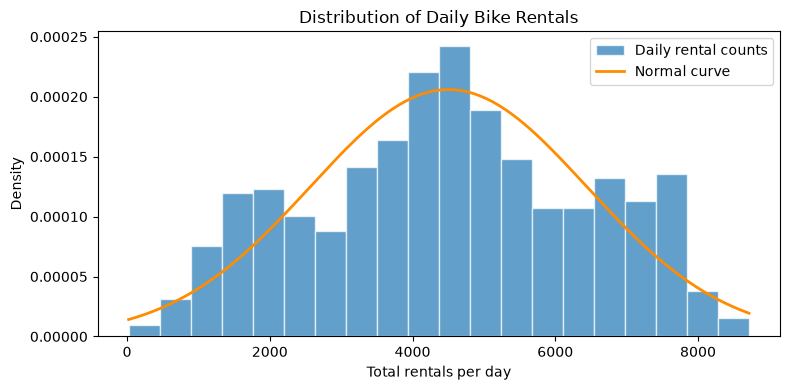

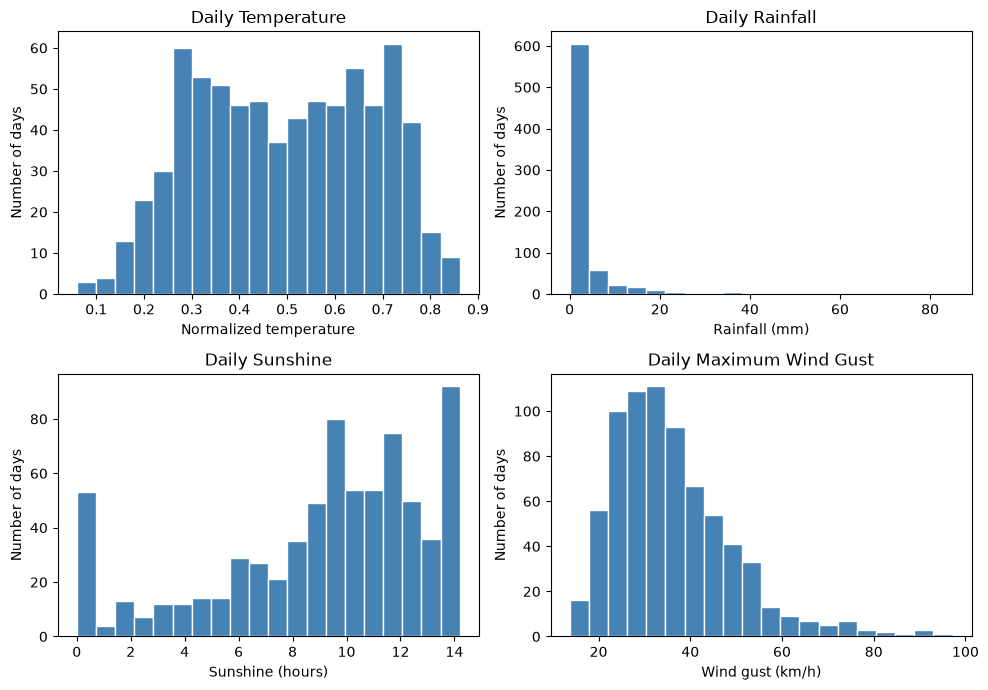

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Compare rental totals on days with and without recorded rain.
rain_group = study_data["rain_sum"].gt(0).map({
    True: "Rain recorded",
    False: "No rain recorded"
})

rain_comparison = (
    study_data.groupby(rain_group)["cnt"]
    .agg(days="size", mean_rentals="mean", median_rentals="median")
    .round(1)
)
rain_comparison.index.name = "Rain group"

display(rain_comparison)

# Calculate a normal curve using the mean and standard deviation of rentals.
rentals = study_data["cnt"]
mean_rentals = rentals.mean()
std_rentals = rentals.std()

x = np.linspace(rentals.min(), rentals.max(), 200)
normal_curve = np.exp(-0.5 * ((x - mean_rentals) / std_rentals) ** 2) / (
    std_rentals * np.sqrt(2 * np.pi)
)

# Use a density scale so the histogram and curve can share the same axis.
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(
    rentals, bins=20, density=True, alpha=0.7,
    edgecolor="white", label="Daily rental counts"
)
ax.plot(x, normal_curve, color="darkorange", linewidth=2, label="Normal curve")
ax.set_title("Distribution of Daily Bike Rentals")
ax.set_xlabel("Total rentals per day")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.show()

weather_plots = [
    (study_data["temp"], "Daily Temperature", "Normalized temperature"),
    (study_data["rain_sum"], "Daily Rainfall", "Rainfall (mm)"),
    (study_data["sunshine_duration"] / 3600, "Daily Sunshine", "Sunshine (hours)"),
    (study_data["wind_gusts_10m_max"], "Daily Maximum Wind Gust", "Wind gust (km/h)")
]

fig, axes = plt.subplots(2, 2, figsize=(10, 7))

for ax, (values, title, x_label) in zip(axes.flat, weather_plots):
    ax.hist(values, bins=20, color="steelblue", edgecolor="white")
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel("Number of days")

fig.tight_layout()
plt.show()


### Rental and Weather Patterns

The median was **4,719 rentals** on days without recorded rain and **4,367** on days with rain, a difference of **352 rentals**. Other factors, such as season and temperature, may also explain part of the difference.

Daily rental counts peaked around **4,000–5,000** and differed from the bell-shaped reference curve. We will check the regression residuals separately.

Temperature showed two broad groups. Rainfall was **right-skewed**, with no rain on **392 days** and a maximum of **85 mm**. Many days had **9–14 hours of sunshine**, and daily maximum wind gusts were most common around **20–40 km/h**.

## Step 8 — Train/Test Split and Distribution Comparison

In this section, I will split the prepared dataset into training and testing sets. I will then compare the distributions of the variables in both sets to check whether they are similar and note any differences.

In [8]:

from sklearn.model_selection import train_test_split

# Split the prepared dataset into training and testing sets.
train_data, test_data = train_test_split(
    study_data,
    test_size=0.30,
    random_state=42
)

print("Total records:", len(study_data))
print("Training records:", len(train_data))
print("Testing records:", len(test_data))


Total records: 731
Training records: 511
Testing records: 220


#### Train/Test Split Observation

I split the dataset into 70% training data and 30% testing data. The training set contains 511 records, and the testing set contains 220 records.

I used `random_state=42` so that we get the same split every time we run the notebook. This gives us enough data to train the regression models while keeping separate data to test them.

I will use the same split for both simple linear regression models and the multiple linear regression model so that we can compare their results fairly.

Since this is a random split, the models are being tested on randomly selected historical days rather than predicting future dates.

### Step 8.1 — Summary Statistics Comparison

In [9]:

# Compare the distributions of important numerical variables
compare_columns = ["cnt", "temp", "hum", "windspeed", "rain_sum"]

train_summary = train_data[compare_columns].describe().loc[
    ["mean", "std", "min", "max"]
]

test_summary = test_data[compare_columns].describe().loc[
    ["mean", "std", "min", "max"]
]

print("Training Data Summary:")
display(train_summary.round(2))

print("Testing Data Summary:")
display(test_summary.round(2))


Training Data Summary:


,cnt,temp,hum,windspeed,rain_sum
mean,4556.87,0.50,0.63,0.19,2.64
std,1909.46,0.18,0.14,0.08,6.25
min,431.00,0.06,0.00,0.02,0.00
max,8714.00,0.86,0.96,0.44,60.90


Testing Data Summary:


,cnt,temp,hum,windspeed,rain_sum
mean,4382.36,0.48,0.61,0.19,3.19
std,1999.28,0.19,0.15,0.08,9.28
min,22.00,0.10,0.19,0.05,0.00
max,8555.00,0.84,0.97,0.51,85.00


###  Train and Test Data Comparison Observation

I compared the training and testing datasets using the mean, standard deviation, minimum, and maximum values.

The average daily rentals are 4,556.87 in the training data and 4,382.36 in the testing data. The standard deviations are also close, which shows that the overall variation in rentals is similar.

The average temperature and humidity values are also similar in both datasets.

However, I noticed that the minimum rental count is much lower in the testing data (22) compared to the training data (431). This shows that there are some differences between the two datasets.

I also noticed that the testing dataset has slightly higher average rainfall (3.19 mm) than the training dataset (2.64 mm). The maximum rainfall is also higher in the testing data, so the rainfall distributions are not exactly the same.

Overall, the training and testing data look reasonably similar based on the variables checked so far, but they are not exactly the same.

### Step 8.2 — Visual Comparison of Training and Testing Distributions

I will use normalized histograms to compare the daily rental distributions in the training and testing datasets. This will help me check whether both datasets have similar patterns and identify any differences.

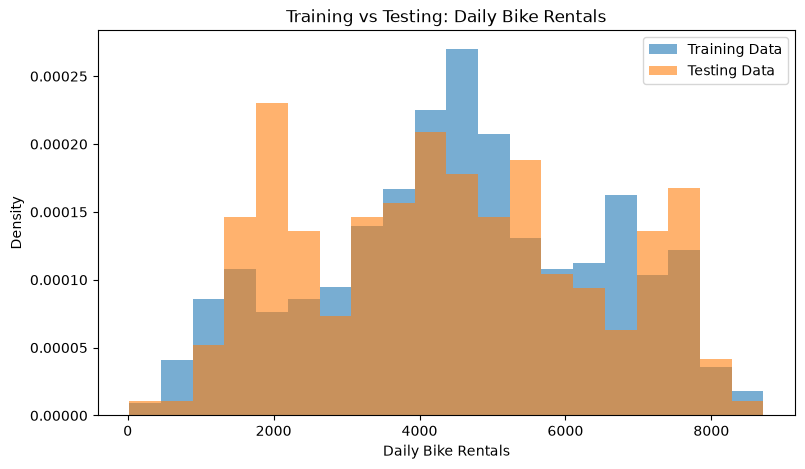

In [10]:

# Compare daily rental distributions
import matplotlib.pyplot as plt
import numpy as np

# Use the same bins for both datasets
bins = np.linspace(study_data["cnt"].min(),
                   study_data["cnt"].max(), 21)

plt.figure(figsize=(9, 5))

plt.hist(train_data["cnt"], bins=bins, density=True,
         alpha=0.6, label="Training Data")

plt.hist(test_data["cnt"], bins=bins, density=True,
         alpha=0.6, label="Testing Data")

plt.xlabel("Daily Bike Rentals")
plt.ylabel("Density")
plt.title("Training vs Testing: Daily Bike Rentals")
plt.legend()
plt.show()


### Daily Rental Distribution — Observation

The training and testing datasets show similar overall rental patterns, with most rental counts between 3,000 and 6,000.

However, the testing data has a higher concentration of days around 2,000 rentals, while the training data has a higher concentration around 4,500 rentals.

Overall, the distributions are reasonably similar, so the split looks suitable for comparing our regression models.

### Step 8.3 — Compare Predictor Distributions

I will compare the distributions of temperature, humidity, wind speed, and rainfall in the training and testing datasets to check whether the weather conditions are similarly represented in both sets.

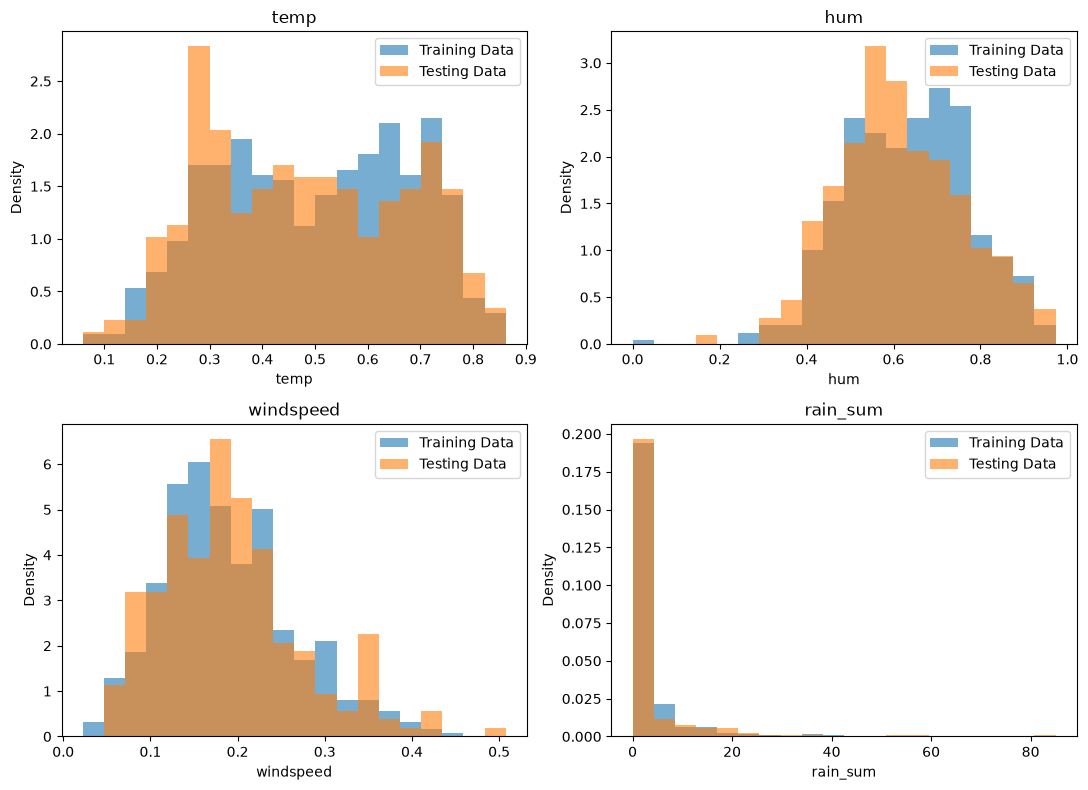

In [11]:

# Compare weather predictor distributions
weather_columns = ["temp", "hum", "windspeed", "rain_sum"]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, column in zip(axes.flat, weather_columns):
    bins = np.linspace(
        study_data[column].min(),
        study_data[column].max(),
        21
    )

    ax.hist(train_data[column], bins=bins, density=True,
            alpha=0.6, label="Training Data")

    ax.hist(test_data[column], bins=bins, density=True,
            alpha=0.6, label="Testing Data")

    ax.set_title(column)
    ax.set_xlabel(column)
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()


### Predictor Distribution — Observation

The training and testing datasets show similar overall distributions for temperature, humidity, wind speed, and rainfall.

Temperature and humidity have some differences in their peaks, but their ranges and general patterns are similar. Wind speed is mostly concentrated between 0.1 and 0.25 in both datasets.

Rainfall is strongly right-skewed, with most days having little or no rain and only a few days having heavy rainfall.

Overall, the selected weather variables are reasonably similar in both datasets, although there are some differences.

### Step 8.4 — Compare Categorical Distributions

I will compare the proportions of seasons, weekdays, and weather conditions in the training and testing datasets to check whether both sets contain similar categories.

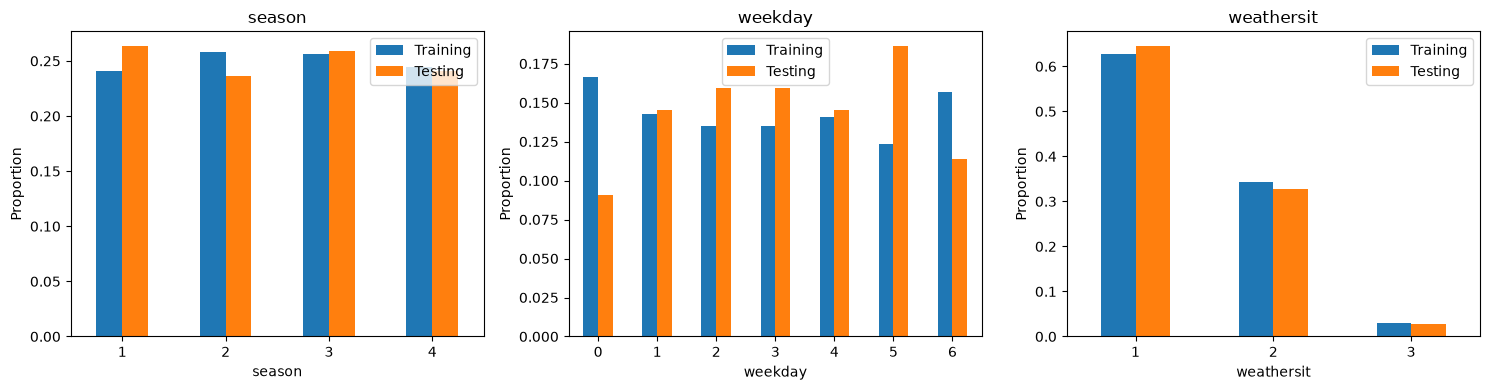

In [12]:

# Compare categorical variable distributions
category_columns = ["season", "weekday", "weathersit"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, column in zip(axes, category_columns):

    # Calculate proportions for each category
    train_counts = train_data[column].value_counts(normalize=True).sort_index()
    test_counts = test_data[column].value_counts(normalize=True).sort_index()

    # Combine the proportions for comparison
    comparison = pd.DataFrame({
        "Training": train_counts,
        "Testing": test_counts
    }).fillna(0)

    comparison.plot(kind="bar", ax=ax)

    ax.set_title(column)
    ax.set_xlabel(column)
    ax.set_ylabel("Proportion")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


### Categorical Distribution — Observation

The training and testing datasets have similar proportions across all four seasons.

The weekday distributions show some differences, especially for weekdays 0, 5, and 6, but all seven weekdays are represented in both datasets.

Weather conditions also show similar patterns, with category 1 being the most common and category 3 being the least common.

Overall, the categorical distributions are reasonably similar, although some differences are present.

## Step 9 — Simple Linear Regression

I will build two simple linear regression models using different weather variables to predict daily bike rentals (`cnt`). I will compare their F-statistics, R² values, and training and testing RMSE to see which model performs better.

### Step 9.1 — Model 1: Temperature

For the first model, I will use temperature (`temp`) to predict daily bike rentals (`cnt`). I want to check whether temperature has a significant linear relationship with rental counts.

In [14]:

import statsmodels.formula.api as smf

# Train Model 1 using temperature
model1 = smf.ols("cnt ~ temp", data=train_data).fit()

# Display regression results
print(model1.summary())


                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.398
Model:                            OLS   Adj. R-squared:                  0.397
Method:                 Least Squares   F-statistic:                     336.5
Date:                Wed, 25 Nov 2026   Prob (F-statistic):           4.47e-58
Time:                        02:39:11   Log-Likelihood:                -4455.3
No. Observations:                 511   AIC:                             8915.
Df Residuals:                     509   BIC:                             8923.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   1222.7835    193.220      6.328      0.0

### Model 1 — Regression Results

The temperature model has an R² value of 0.398, which means temperature explains about 39.8% of the variation in daily bike rentals.

The temperature coefficient is positive (6651.15), showing that higher temperatures are associated with more rentals.

The F-statistic is 336.5, with a very small p-value (4.47e-58). This shows that temperature has a statistically significant linear relationship with daily rentals.

However, temperature alone does not explain all the changes in rental counts, so other variables may also be important.

### Step 9.2 — Model 1: Training and Testing RMSE

I will calculate the RMSE for both training and testing data to check how accurately the temperature model predicts daily bike rentals. Lower RMSE values indicate better predictions.

In [15]:

from sklearn.metrics import mean_squared_error
import numpy as np

# Predict rentals using Model 1
model1_train_pred = model1.predict(train_data)
model1_test_pred = model1.predict(test_data)

# Calculate RMSE
model1_train_rmse = np.sqrt(
    mean_squared_error(train_data["cnt"], model1_train_pred)
)

model1_test_rmse = np.sqrt(
    mean_squared_error(test_data["cnt"], model1_test_pred)
)

print(f"Model 1 Training RMSE: {model1_train_rmse:.2f}")
print(f"Model 1 Testing RMSE: {model1_test_rmse:.2f}")


Model 1 Training RMSE: 1480.05
Model 1 Testing RMSE: 1569.03


### Model 1 — RMSE Observation

The temperature model has a training RMSE of 1480.05 and a testing RMSE of 1569.03.

The testing RMSE is slightly higher than the training RMSE, which means the model makes somewhat larger prediction errors on unseen data.

The values are reasonably close, so there is no strong indication of overfitting from this comparison. However, the prediction errors are still quite large, showing that temperature alone is not enough to predict daily rentals accurately.

### Step 9.3 — Model 2: Rainfall

For the second model, I will use daily rainfall (`rain_sum`) to predict bike rentals (`cnt`). I want to check whether rainfall has a significant linear relationship with rental counts and compare its performance with the temperature model.

In [16]:

# Train Model 2 using rainfall
model2 = smf.ols("cnt ~ rain_sum", data=train_data).fit()

# Display regression results
print(model2.summary())


                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.049
Model:                            OLS   Adj. R-squared:                  0.047
Method:                 Least Squares   F-statistic:                     26.06
Date:                Wed, 25 Nov 2026   Prob (F-statistic):           4.68e-07
Time:                        02:40:57   Log-Likelihood:                -4572.2
No. Observations:                 511   AIC:                             9148.
Df Residuals:                     509   BIC:                             9157.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   4734.6497     89.520     52.889      0.0

### Model 2 — Regression Results

The rainfall model has an R² value of 0.049, meaning rainfall explains only 4.9% of the variation in daily bike rentals.

The rainfall coefficient is negative (-67.46), showing that higher rainfall is associated with fewer bike rentals.

The F-statistic is 26.06, with a small p-value (4.68e-07), so the relationship is statistically significant.

Compared with the temperature model, rainfall explains much less variation in rental counts.

### Step 9.4 — Model 2: Training and Testing RMSE

I will calculate the training and testing RMSE for the rainfall model to check its prediction errors and compare them with the temperature model.

In [17]:

# Predict rentals using Model 2
model2_train_pred = model2.predict(train_data)
model2_test_pred = model2.predict(test_data)

# Calculate training and testing RMSE
model2_train_rmse = np.sqrt(
    mean_squared_error(train_data["cnt"], model2_train_pred)
)

model2_test_rmse = np.sqrt(
    mean_squared_error(test_data["cnt"], model2_test_pred)
)

print(f"Model 2 Training RMSE: {model2_train_rmse:.2f}")
print(f"Model 2 Testing RMSE: {model2_test_rmse:.2f}")


Model 2 Training RMSE: 1860.56
Model 2 Testing RMSE: 1891.61


### Model 2 — RMSE Observation

The rainfall model has a training RMSE of 1860.56 and a testing RMSE of 1891.61.

The training and testing errors are close, so there is no strong indication of overfitting from these results. However, both RMSE values are higher than those of the temperature model.

This shows that rainfall alone is less accurate than temperature for predicting daily bike rentals.

### Step 9.5 — Comparison of Both Models

I will compare the F-statistic, R², training RMSE, and testing RMSE of both models to identify which weather variable predicts daily bike rentals more accurately.

In [19]:

# Compare both simple linear regression models
comparison_results = pd.DataFrame({
    "Model": ["Temperature", "Rainfall"],
    "F-statistic": [model1.fvalue, model2.fvalue],
    "R-squared": [model1.rsquared, model2.rsquared],
    "Training RMSE": [model1_train_rmse, model2_train_rmse],
    "Testing RMSE": [model1_test_rmse, model2_test_rmse]
})

display(
    comparison_results.style.format({
        "F-statistic": "{:.2f}",
        "R-squared": "{:.3f}",
        "Training RMSE": "{:.2f}",
        "Testing RMSE": "{:.2f}"
    })
)

,Model,F-statistic,R-squared,Training RMSE,Testing RMSE
0,Temperature,336.54,0.398,1480.05,1569.03
1,Rainfall,26.06,0.049,1860.56,1891.61


### Model Comparison — Final Observation

I compared both simple linear regression models using the F-statistic, R², training RMSE, and testing RMSE.

The temperature model has a higher F-statistic (336.54) and R² (0.398) than the rainfall model (26.06 and 0.049). Both models are statistically significant, but temperature explains more variation in daily rentals.

The temperature model also has lower training RMSE (1480.05) and testing RMSE (1569.03), compared with the rainfall model (1860.56 and 1891.61).

Based on these results, I found that **temperature is the better predictor** because it explains more variation and produces smaller prediction errors on both training and testing data.

However, temperature alone does not explain all the changes in rental counts. Using multiple variables together may improve prediction accuracy.

### Step 9.6 — Residual Analysis for Both SLR Models

I will compare the residuals of the temperature and rainfall models to understand their prediction errors. A residual is the difference between the actual rental count and the predicted rental count.

By plotting residuals against predicted values, I can check whether the errors are randomly distributed around zero or show any noticeable patterns.

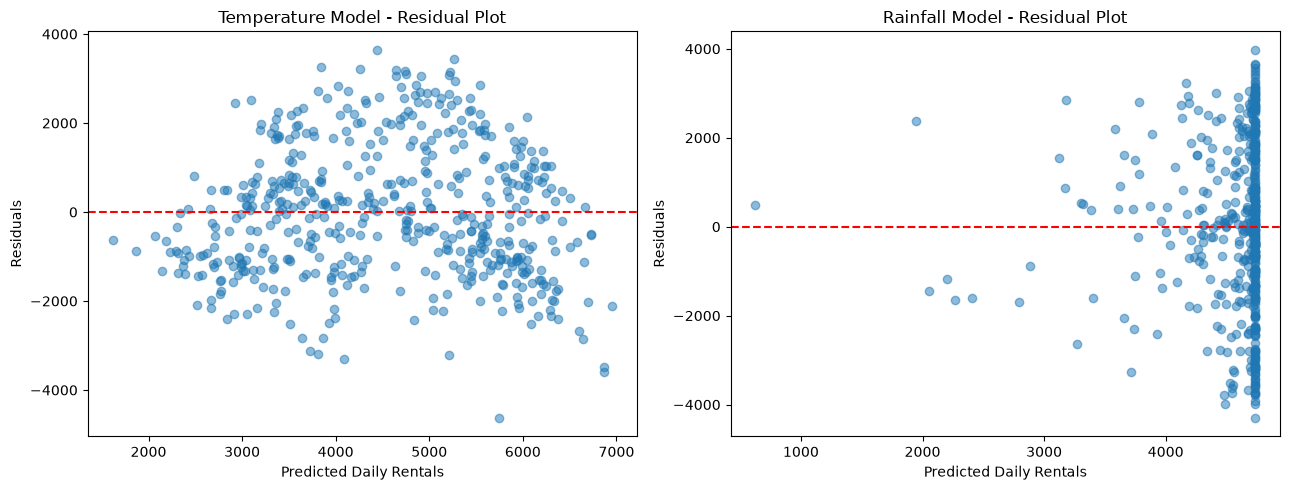

In [20]:
import matplotlib.pyplot as plt

# Calculate predictions using the training dataset
temp_predictions = model1.predict(train_data)
rain_predictions = model2.predict(train_data)

# Calculate residuals
temp_residuals = train_data["cnt"] - temp_predictions
rain_residuals = train_data["cnt"] - rain_predictions

# Create residual plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(temp_predictions, temp_residuals, alpha=0.5)
axes[0].axhline(y=0, color="red", linestyle="--")
axes[0].set_title("Temperature Model - Residual Plot")
axes[0].set_xlabel("Predicted Daily Rentals")
axes[0].set_ylabel("Residuals")

axes[1].scatter(rain_predictions, rain_residuals, alpha=0.5)
axes[1].axhline(y=0, color="red", linestyle="--")
axes[1].set_title("Rainfall Model - Residual Plot")
axes[1].set_xlabel("Predicted Daily Rentals")
axes[1].set_ylabel("Residuals")

plt.tight_layout()
plt.show()

####  Residual Plot Observation

I compared the residual plots of both simple linear regression models to understand their prediction errors.

For the temperature model, the residuals are spread above and below zero, but I noticed some patterns in the distribution. This suggests that temperature alone cannot explain all the changes in daily bike rentals.

For the rainfall model, most residuals are concentrated around similar predicted rental values, with a wide range of errors. This shows that rainfall alone does not predict daily rentals very well.

Overall, the temperature model performs better, which is consistent with its higher R² and lower RMSE values. However, both models still have prediction errors, so using multiple variables may help improve the results.

## Step 10 — Multiple linear regression

### Step 10.1 — Train the full model

In Step 9, we used temperature and rainfall separately to predict daily rentals. Now we use weather and calendar information together. Two days could have the same temperature, for example, even if one is a rainy holiday and the other is a sunny weekday.

We trained the model on the same 511 days using all 25 predictors. Our target, `cnt`, is the number of bike rentals in a day.

In [18]:
formula = "cnt ~ " + " + ".join(predictors)
model3 = smf.ols(formula, data=train_data).fit()

print(formula)
print(model3.summary())

cnt ~ season + yr + mnth + holiday + weekday + weathersit + temp + hum + windspeed + rain_sum + snowfall_sum + precipitation_hours + shortwave_radiation_sum + daylight_duration + sunshine_duration + wind_gusts_10m_max + wind_speed_10m_max + wind_direction + temp_range + cloud_cover_mean + cloud_range + pressure_msl_mean + pressure_range + relative_humidity_2m_min + dew_point_2m_mean
                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.879
Model:                            OLS   Adj. R-squared:                  0.866
Method:                 Least Squares   F-statistic:                     68.38
Date:                Wed, 25 Nov 2026   Prob (F-statistic):          1.48e-180
Time:                        19:41:32   Log-Likelihood:                -4045.2
No. Observations:                 511   AIC:                             8190.
Df Residuals:                     461   BIC:                 

### What we learned from the model

The training R² is about 0.88. This means the model explains about 88% of the variation in daily rentals across the training days. The overall F-test has a very small p-value, which gives us evidence that at least one predictor helps explain rentals.

The coefficient for `yr` is about 2,019. When we hold the other predictors fixed, the model predicts about 2,019 more rentals for a day in 2012 than for a day in 2011.

### Step 10.2 — Check one prediction

We predicted rentals for the 220 test days. For each day, we subtracted the predicted count from the actual count. This difference is called a **residual**. A positive residual means our prediction was too low.

In [19]:
multiple_train_pred = model3.predict(train_data)
multiple_test_pred = model3.predict(test_data)

test_examples = test_data[["date", "cnt"]].rename(columns={"cnt": "Actual"}).copy()
test_examples["Predicted"] = multiple_test_pred
test_examples["Residual"] = test_examples["Actual"] - test_examples["Predicted"]
display(test_examples.head().round(0))

,date,Actual,Predicted,Residual
703,2012-12-04,6606,6237.0,369.0
33,2011-02-03,1550,1664.0,-114.0
300,2011-10-28,3747,3676.0,71.0
456,2012-04-01,6041,5030.0,1011.0
633,2012-09-25,7538,7827.0,-289.0


On December 4, 2012, we predicted about **6,237 rentals**. The actual count was **6,606**, so we underestimated rentals by about **369** that day.

### Step 10.3 — Which predictors should we keep?

Our full model uses all 25 predictors. Some describe similar things. For example, once we know how many hours it rained, how much more can we learn from the amount of rain?

We used **backward elimination** on the 511 training days. In each round, we checked which predictor had the largest p-value after accounting for the others. If its p-value was above 0.05, we removed it and fitted the model again. We stopped when every remaining predictor met our cutoff. For a predictor like weekday, we tested its categories together.

In [20]:
selected = predictors.copy()
refined_model = model3
removals = []

while selected:
    tests = refined_model.wald_test_terms(skip_single=False, scalar=True).table
    p_values = tests.drop(index="Intercept")["pvalue"].astype(float)
    weakest = p_values.idxmax()
    if p_values[weakest] <= 0.05:
        break

    removals.append({"Removed predictor": weakest, "p-value at removal": p_values[weakest]})
    selected.remove(weakest)
    remaining_terms = " + ".join(selected) or "1"
    refined_model = smf.ols("cnt ~ " + remaining_terms, data=train_data).fit()

removal_table = pd.DataFrame(removals)
removal_table.index = pd.RangeIndex(1, len(removal_table) + 1, name="Round")
display(removal_table.round(4))

,Removed predictor,p-value at removal
Round,,
1,wind_speed_10m_max,0.9851
2,cloud_range,0.8922
3,cloud_cover_mean,0.7619
4,daylight_duration,0.6942
5,pressure_range,0.5918
6,wind_direction,0.5747
7,snowfall_sum,0.5647
8,temp,0.4957
9,temp_range,0.3018


### Step 10.4 — Look at the smaller model

Each row in the table shows one round. We removed maximum wind speed first because it had the largest p-value, about 0.985. We checked the p-values again after each removal because the evidence for one predictor can change when we remove another.

In [21]:
print(f"Predictors removed: {len(removals)}")
print(f"Predictors kept: {len(selected)}")
for predictor in selected:
    print(predictor)

Predictors removed: 15
Predictors kept: 10
season
yr
mnth
holiday
weekday
precipitation_hours
sunshine_duration
wind_gusts_10m_max
relative_humidity_2m_min
dew_point_2m_mean


**What we kept.** We removed 15 predictors and kept 10. Five describe the calendar, including season, year, month, holiday and weekday. The five weather predictors are hours of precipitation, sunshine duration, maximum wind gust, minimum relative humidity and average dew point.

**Why temperature dropped out.** In Step 9, temperature was the better of our two single predictors. Once our model also knew the season, month and dew point, temperature added too little information to meet our cutoff. We used only the training days to make these decisions.

### Step 10.5 — Compare all four models on the same days

We gave every model the same 220 test days. **RMSE** measures prediction error in rentals per day and gives more weight to large misses. A lower test RMSE means the model predicted these days more accurately.

We also report the overall F-statistic and **adjusted R²** from training. Adjusted R² accounts for how many coefficients the model uses. This helps us compare how well the full and smaller models fit the training days.

In [22]:
models = {
    "Temperature only": model1,
    "Rainfall only": model2,
    "Full model (25 predictors)": model3,
    "Smaller model (10 predictors)": refined_model,
}
scores = []
for name, fitted in models.items():
    train_predictions = fitted.predict(train_data)
    test_predictions = fitted.predict(test_data)
    scores.append({
        "Model": name,
        "F-statistic": fitted.fvalue,
        "Adjusted R²": fitted.rsquared_adj,
        "Training RMSE": np.sqrt(mean_squared_error(train_data["cnt"], train_predictions)),
        "Test RMSE": np.sqrt(mean_squared_error(test_data["cnt"], test_predictions)),
    })

model_scores = pd.DataFrame(scores).set_index("Model")
display(model_scores.round({"F-statistic": 2, "Adjusted R²": 4, "Training RMSE": 2, "Test RMSE": 2}))

,F-statistic,Adjusted R²,Training RMSE,Test RMSE
Model,,,,
Temperature only,336.54,0.3968,1480.05,1569.03
Rainfall only,26.06,0.0468,1860.56,1891.61
Full model (25 predictors),68.38,0.8662,663.40,651.19
Smaller model (10 predictors),123.49,0.8664,678.56,676.98


The full and smaller models had almost the same adjusted R² on the training days (0.8662 and 0.8664). On the test days, the full model had the lowest RMSE at **651.19**. The smaller model scored **676.98**, an increase of **25.79 rentals per day** on the error measure.

The smaller model's overall F-statistic was **123.49**, with a very small p-value. Its predictors jointly helped explain rental differences. Its year coefficient was about **+2,048**. With its other nine predictors held fixed, the smaller model estimated about 2,048 more daily rentals in 2012 than in 2011.

### Step 10.6 — Where did our predictions miss?

We plotted the errors for the full and smaller models on the same scale. Each dot represents a test day. Above zero, we predicted too few rentals. Below zero, we predicted too many.

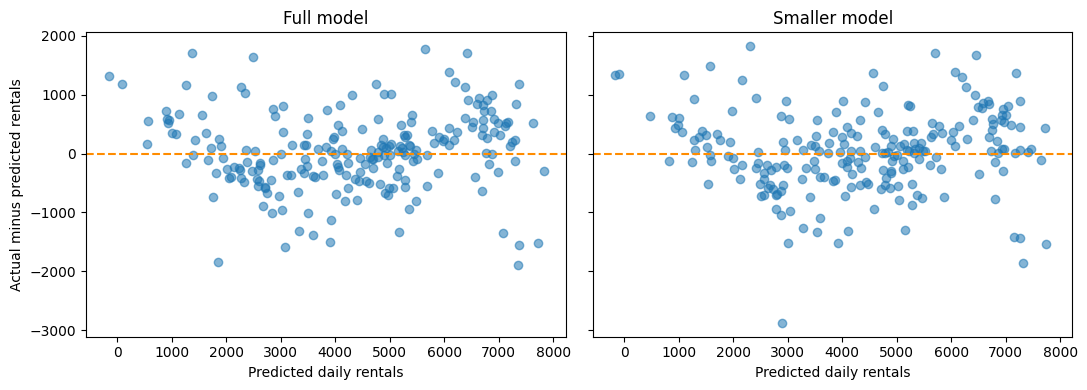

Largest underestimate for the full model: 1,768 rentals
Largest overestimate for the full model: 1,891 rentals


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for ax, name, fitted in zip(axes, ["Full model", "Smaller model"], [model3, refined_model]):
    predicted = fitted.predict(test_data)
    residual = test_data["cnt"] - predicted
    ax.scatter(predicted, residual, alpha=0.55)
    ax.axhline(0, color="darkorange", linestyle="--")
    ax.set(title=name, xlabel="Predicted daily rentals")

axes[0].set_ylabel("Actual minus predicted rentals")
fig.tight_layout()
plt.show()

full_errors = test_data["cnt"] - multiple_test_pred
print(f"Largest underestimate for the full model: {full_errors.max():,.0f} rentals")
print(f"Largest overestimate for the full model: {-full_errors.min():,.0f} rentals")

Even the full model missed some days by a wide margin. Its largest overestimate was about **1,891 rentals**, and its largest underestimate was about **1,768 rentals**.

## Step 11 — Group conclusion

We wanted to know whether combining weather and calendar details would help us predict bike rentals. On our 220 historical test days, it did. Temperature alone gave a test RMSE of **1,569.03** and rain alone gave **1,891.61**. With all 25 predictors, the error score fell to **651.19**, about **58.5% lower** than our better single-predictor model. We would choose the full model for prediction accuracy on this split.

**What we can say in our presentation.** “We gave every model the same 220 days. Using weather and calendar details together gave us the lowest error. We also tried using just 10 predictors. That model came close, so we could use fewer inputs if collecting all 25 was difficult.”

**What we would check next.** Our test days came from the same two years as the training days, and we used recorded weather. To see how well this would work for future planning, we would train on earlier dates, test on later dates and use the weather forecasts available at the time.